In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import os
import torch

# Create data directory if it doesn't exist
data_dir = '../WeatherData'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)

# Example: Downloading a subset of ERA5 data via CDS API
# Note: This requires a .cdsapirc file with your UID and API Key
# See: https://cds.climate.copernicus.eu/how-to-api

"""
import cdsapi

c = cdsapi.Client()

c.retrieve(
    'reanalysis-era5-single-levels',
    {
        'product_type': 'reanalysis',
        'format': 'netcdf',
        'variable': [
            '2m_temperature', 'total_precipitation',
        ],
        'year': '2023',
        'month': '01',
        'day': [
            '01', '02', '03',
        ],
        'time': [
            '00:00', '06:00', '12:00', '18:00',
        ],
    },
    os.path.join(data_dir, 'era5_sample.nc')
)
"""

# Since API keys are required for CDS, let's also provide a way to download 
# publicly available sample data from xarray's tutorial or NOAA OISST (Open Data)
print("Downloading sample high-dimensional weather data (NOAA OISST)...")

# NOAA Optimum Interpolated SST (Sea Surface Temperature) - Daily, 0.25 deg grid
# This is a good example of high-dimensional gridded time series
url = "https://www.ncei.noaa.gov/data/sea-surface-temperature-optimum-interpolation/v2.1/access/avhrr/202301/oisst-avhrr-v02r01.20230101.nc"
target_path = os.path.join(data_dir, 'oisst_sample.nc')

if not os.path.exists(target_path):
    import requests
    response = requests.get(url)
    with open(target_path, 'wb') as f:
        f.write(response.content)
    print(f"Downloaded: {target_path}")
else:
    print(f"File already exists: {target_path}")

# Load and inspect
ds = xr.open_dataset(target_path)
print("\nDataset Summary:")
print(ds)

# Show dimensions
print(f"\nDimensions: {dict(ds.dims)}")
print(f"Variables: {list(ds.data_vars)}")


File already exists: ../WeatherData/oisst_sample.nc

Dataset Summary:
<xarray.Dataset> Size: 17MB
Dimensions:  (time: 1, zlev: 1, lat: 720, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 8B 2023-01-01T12:00:00
  * zlev     (zlev) float32 4B 0.0
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    sst      (time, zlev, lat, lon) float32 4MB ...
    anom     (time, zlev, lat, lon) float32 4MB ...
    err      (time, zlev, lat, lon) float32 4MB ...
    ice      (time, zlev, lat, lon) float32 4MB ...
Attributes: (12/37)
    Conventions:                CF-1.6, ACDD-1.3
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    references:                 Reynolds, et al.(2007) Daily High-Resolution-...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    id:                         oisst-avhrr-v02r0

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_33206/1090242169.py:66: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"\nDimensions: {dict(ds.dims)}")


In [2]:
# Extracting 2D array: (locations, time) for 100 time points
print("\nExtracting 2D array for 100 time points...")

# Note: The following code assumes 100 daily files have been downloaded to 'WeatherData/'
# oisst-avhrr-v02r01.20230101.nc to oisst-avhrr-v02r01.20230410.nc
files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.startswith('oisst-avhrr-v02r01') and f.endswith('.nc')])

if len(files) >= 100:
    # Open first 100 files
    ds_100 = xr.open_mfdataset(files[:100], combine='by_coords')
    
    # Extract Sea Surface Temperature (sst)
    # Dimensions are (time, zlev, lat, lon)
    # Define Atlantic square patch: Lat 0 to 50, Lon 290 to 340 (approx)
    lat_min, lat_max = 0, 50
    lon_min, lon_max = 290, 340
    
    # We squeeze to remove zlev (depth) which has size 1 and slice to Atlantic patch
    sst = ds_100.sst.squeeze().sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
    
    # Flatten spatial dimensions (lat, lon) into one 'location' dimension
    n_time, n_lat, n_lon = sst.shape
    
    # Each row should represent temperature at a specific location over time
    # Final shape: (n_locations, n_time)
    sst_2d = sst.values.reshape(n_time, -1).T
    
    print(f"Resulting 2D array shape: {sst_2d.shape}")
    print(f"Example data (first location, first 5 time points): {sst_2d[0, :5]}")
    
    # Save for later use
    np.save(os.path.join(data_dir, 'sst_2d_array.npy'), sst_2d)
else:
    print(f"Not enough files found in {data_dir}. Expected 100, found {len(files)}.")



Extracting 2D array for 100 time points...
Resulting 2D array shape: (40000, 100)
Example data (first location, first 5 time points): [nan nan nan nan nan]


/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/dask/array/numpy_compat.py:56: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/dask/array/numpy_compat.py:56: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/dask/array/numpy_compat.py:56: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/dask/array/numpy_compat.py:56: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)


In [3]:
sst_2d.shape

(40000, 100)

In [4]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

# Load data if not in memory
if 'sst_2d' not in locals():
    save_path = os.path.join(data_dir, 'sst_2d_array.npy')
    if os.path.exists(save_path):
        sst_2d = np.load(save_path)
    else:
        print(f"Error: {save_path} not found. Please ensure the data extraction block has run successfully.")
        # Alternatively, we could raise an error or handle it differently
        raise NameError("sst_2d is not defined and saved file not found.")

# 1. Filter out locations with NaNs (Land) and low variance
print("Filtering out land locations (NaNs) and low variance locations...")
mask_nan = ~np.isnan(sst_2d).any(axis=1)
sst_valid_temp = sst_2d[mask_nan]

# Calculate standard deviation for each valid location
sst_std_temp = np.std(sst_valid_temp, axis=1)

# Filter out locations with very little standard deviation (e.g., < 0.01)
std_threshold = 0.01
mask_std = sst_std_temp > std_threshold
sst_valid = sst_valid_temp[mask_std]

print(f"Total locations: {sst_2d.shape[0]}")
print(f"Valid sea locations: {sst_valid_temp.shape[0]}")
print(f"Locations after variance filtering (std > {std_threshold}): {sst_valid.shape[0]}")

# 2. Z-score the rows (normalize each location's time series)
print("Z-scoring the rows...")
sst_mean_all = np.mean(sst_valid, axis=1, keepdims=True)
sst_std_all = np.std(sst_valid, axis=1, keepdims=True) + 1e-8
sst_valid_norm = (sst_valid - sst_mean_all) / sst_std_all

# 3. Subsample for efficiency (DensMAP can be slow on 700k points)
# We'll take 100,000 points as a representative sample
n_sample = 100000
indices = None
if sst_valid_norm.shape[0] > n_sample:
    indices = np.random.choice(sst_valid_norm.shape[0], n_sample, replace=False)
    sst_sample = sst_valid_norm[indices]
    mean_temp_sample = sst_mean_all[indices].flatten()
else:
    sst_sample = sst_valid_norm
    mean_temp_sample = sst_mean_all.flatten()
    indices = np.arange(sst_valid_norm.shape[0])

print(f"Applying DensMAP to {sst_valid.shape[0]} locations...")

# 3. Apply DensMAP
reducer = umap.UMAP(
    densmap=True, 
    dens_lambda=2,
    n_neighbors=100, 
)
embedding = reducer.fit_transform(sst_sample)



Filtering out land locations (NaNs) and low variance locations...
Total locations: 40000
Valid sea locations: 36729
Locations after variance filtering (std > 0.01): 36729
Z-scoring the rows...
Applying DensMAP to 36729 locations...


Visualizing DensMAP projection...


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_33206/773340977.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


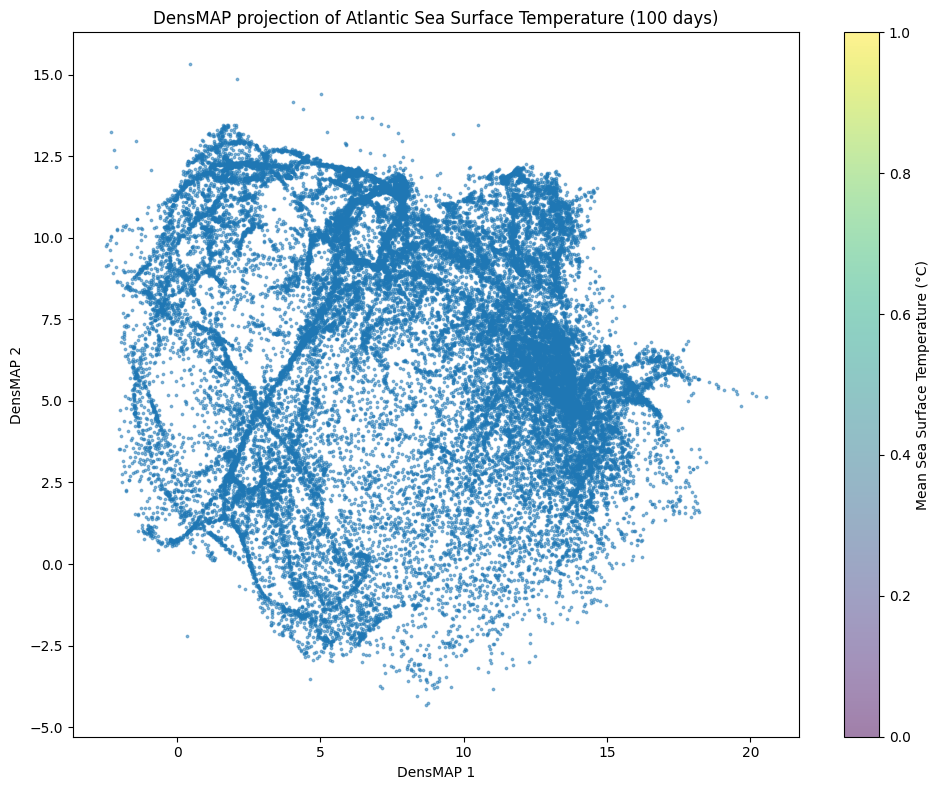

In [5]:

# 4. Visualize results
print("Visualizing DensMAP projection...")
plt.figure(figsize=(10, 8))

plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    cmap='turbo',
    s=3,
    alpha=0.5
)
plt.colorbar(label='Mean Sea Surface Temperature (°C)')
plt.title('DensMAP projection of Atlantic Sea Surface Temperature (100 days)')
plt.xlabel('DensMAP 1')
plt.ylabel('DensMAP 2')
plt.tight_layout()

# Save figure
if not os.path.exists('../Figures'):
    os.makedirs('../Figures')
plt.savefig('../Figures/weather_densmap.png', dpi=300)
plt.show()

In [6]:
sst_sample.shape,mean_temp_sample.shape

((36729, 100), (36729,))

In [7]:
sst_valid.shape

(36729, 100)

Computing mean speed of time series...
Creating side-by-side visualization...


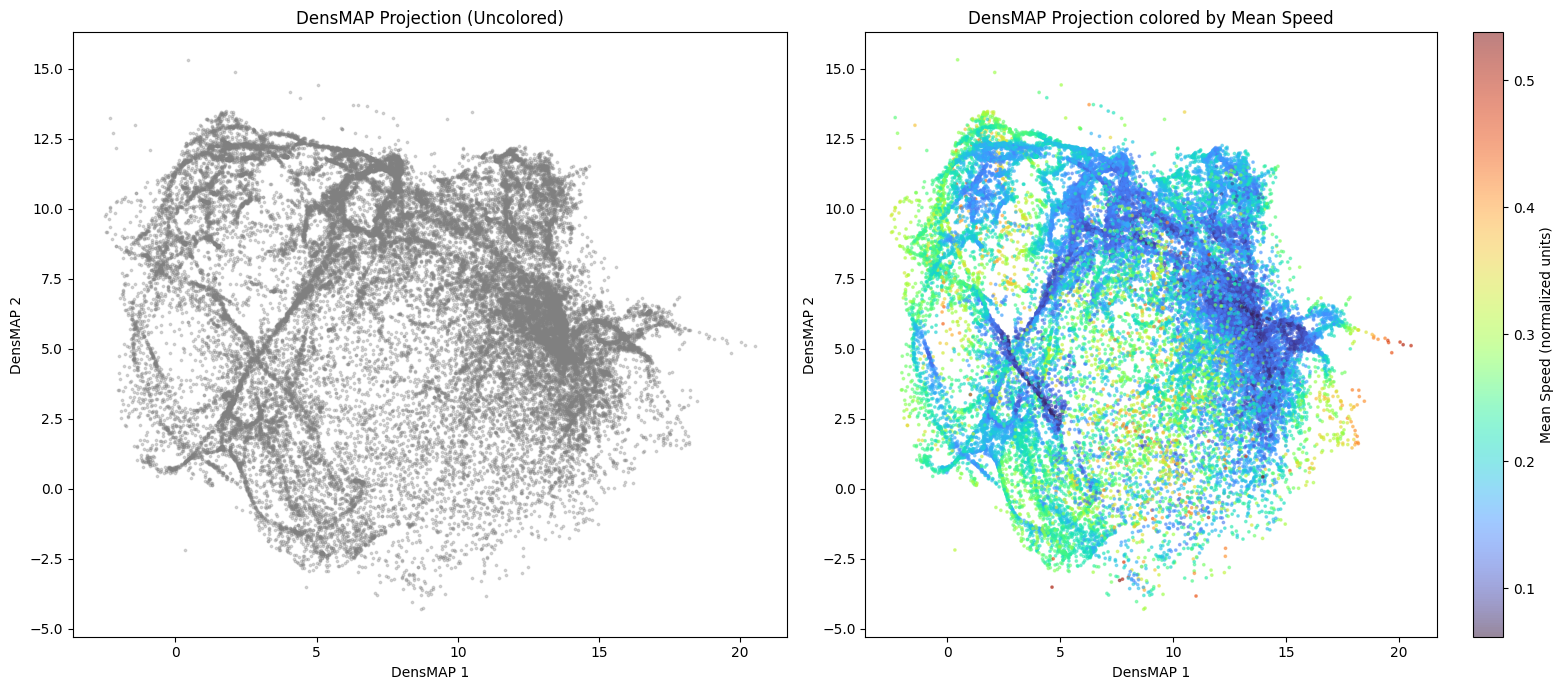

In [8]:
# 5. Compute mean speed and visualize
print("Computing mean speed of time series...")

# Speed = mean(abs(diff(sst_valid_norm)))
# Calculate for all valid locations first, then subsample using the same indices
sst_diff = np.diff(sst_valid_norm, axis=1)
speed_all = np.mean(np.abs(sst_diff), axis=1)
speed_sample = speed_all[indices]

print("Creating side-by-side visualization...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Left: Gray
ax1.scatter(
    embedding[:, 0], 
    embedding[:, 1], 
    color='gray', 
    s=3, 
    alpha=0.3
)
ax1.set_title('DensMAP Projection (Uncolored)')
ax1.set_xlabel('DensMAP 1')
ax1.set_ylabel('DensMAP 2')

# Right: Colored by Mean Speed
sc = ax2.scatter(
    embedding[:, 0], 
    embedding[:, 1], 
    c=speed_sample, 
    cmap='turbo', 
    s=3, 
    alpha=0.5
)
plt.colorbar(sc, ax=ax2, label='Mean Speed (normalized units)')
ax2.set_title('DensMAP Projection colored by Mean Speed')
ax2.set_xlabel('DensMAP 1')
ax2.set_ylabel('DensMAP 2')

plt.tight_layout()

# Save figure
plt.savefig('../Figures/weather_speed_manifold.png', dpi=300)
plt.show()


In [9]:
# 10. Create an animation of Temperature as a function of time and location
import matplotlib.animation as animation
from IPython.display import HTML

print("\nPreparing temperature animation...")

# Load full 3D data if available, or reconstruct from sst_2d if possible
# But it's better to use the xarray dataset directly for spatial structure
files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.startswith('oisst-avhrr-v02r01') and f.endswith('.nc')])

if len(files) >= 10: # We'll use at least 10 days for a short animation
    n_days_anim = min(30, len(files)) # Use up to 30 days for the animation
    ds_anim = xr.open_mfdataset(files[:n_days_anim], combine='by_coords')
    
    # Define Atlantic square patch: Lat 0 to 50, Lon 290 to 340
    lat_min, lat_max = 0, 50
    lon_min, lon_max = 290, 340
    sst_anim = ds_anim.sst.squeeze().sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
    
    # Z-score the time series for each location in the animation data
    # Dimensions of sst_anim are (time, lat, lon)
    # We want to z-score along the time dimension (0)
    sst_anim_mean = sst_anim.mean(dim='time')
    sst_anim_std = sst_anim.std(dim='time') + 1e-8
    sst_anim_norm = (sst_anim - sst_anim_mean) / sst_anim_std
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Determine global min/max for colorbar consistency
    v_min = float(sst_anim_norm.min().values)
    v_max = float(sst_anim_norm.max().values)
    
    # Initial frame
    im = ax.imshow(sst_anim_norm[0], cmap='turbo', origin='lower', 
                   extent=[float(sst_anim.lon.min()), float(sst_anim.lon.max()), float(sst_anim.lat.min()), float(sst_anim.lat.max())],
                   vmin=v_min, vmax=v_max)
    
    cbar = plt.colorbar(im, ax=ax, label='Normalized Temperature (z-score)')
    title = ax.set_title(f'Atlantic Sea Surface Temperature (Z-scored) - {pd.to_datetime(sst_anim.time[0].values).strftime("%Y-%m-%d")}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

    def update(frame):
        im.set_array(sst_anim_norm[frame])
        title.set_text(f'Atlantic Sea Surface Temperature (Z-scored) - {pd.to_datetime(sst_anim.time[frame].values).strftime("%Y-%m-%d")}')
        return [im, title]

    ani = animation.FuncAnimation(fig, update, frames=n_days_anim, interval=200, blit=False)
    
    # Save animationw
    os.makedirs('../Movies', exist_ok=True)
    save_path = '../Movies/weather_temp_animation.mp4'
    ani.save(save_path, writer='ffmpeg')
    print(f"Animation saved to: {save_path}")
    
    plt.close(fig)
else:
    print(f"Not enough files for animation. Found {len(files)}.")



Preparing temperature animation...
Animation saved to: ../Movies/weather_temp_animation.mp4



Preparing DensMAP temperature animation...
DensMAP animation saved to: ../Movies/weather_densmap_temp_animation.mp4

Setting up interactive DensMAP explorer...


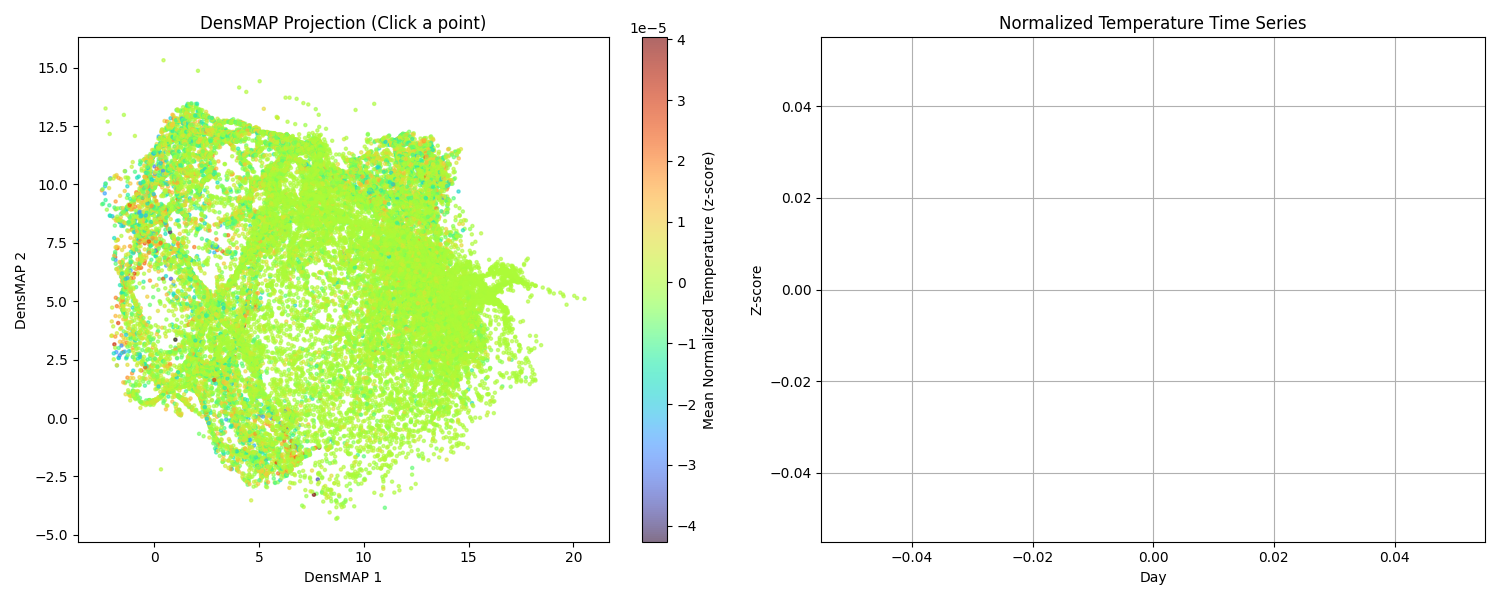

In [10]:
# 11. Create an animation of the DensMAP projection colored by temperature (z-scored) over time
print("\nPreparing DensMAP temperature animation...")

if 'embedding' in locals() and 'sst_sample' in locals():
    n_time = sst_sample.shape[1]
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Determine global min/max for colorbar consistency
    v_min = float(np.nanmin(sst_sample))
    v_max = float(np.nanmax(sst_sample))
    
    # Initial scatter plot
    sc = ax.scatter(
        embedding[:, 0], 
        embedding[:, 1], 
        c=sst_sample[:, 0], 
        cmap='turbo', 
        s=3, 
        alpha=0.5,
        vmin=v_min,
        vmax=v_max
    )
    
    cbar = plt.colorbar(sc, ax=ax, label='Normalized Temperature (z-score)')
    title = ax.set_title(f'DensMAP Projection colored by Z-scored Temperature - Day 0')
    ax.set_xlabel('DensMAP 1')
    ax.set_ylabel('DensMAP 2')

    def update_densmap(frame):
        sc.set_array(sst_sample[:, frame])
        title.set_text(f'DensMAP Projection colored by Z-scored Temperature - Day {frame}')
        return [sc, title]

    ani_densmap = animation.FuncAnimation(fig, update_densmap, frames=n_time, interval=200, blit=False)
    
    # Save animation
    os.makedirs('../Movies', exist_ok=True)
    save_path_densmap = '../Movies/weather_densmap_temp_animation.mp4'
    ani_densmap.save(save_path_densmap, writer='ffmpeg')
    print(f"DensMAP animation saved to: {save_path_densmap}")
    
    plt.close(fig)
else:
    print("Required variables (embedding, sst_valid, indices) not found. Skip DensMAP animation.")

# 12. Interactive GUI for exploring the DensMAP projection
# This requires %matplotlib widget for interactivity in Jupyter/VS Code/PyCharm
# Note: In some environments, you might need to run this cell twice or ensure ipympl is installed.
get_ipython().run_line_magic('matplotlib', 'widget')

import matplotlib.pyplot as plt
from scipy.spatial import KDTree

print("\nSetting up interactive DensMAP explorer...")

if 'embedding' in locals() and 'sst_sample' in locals():
    # sst_sample is already z-scored
    
    # Create a KDTree for fast nearest-neighbor lookup
    tree = KDTree(embedding)

    # Create figure with two subplots: Projection and Time Series
    fig, (ax_proj, ax_ts) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Scatter plot on the left
    sc = ax_proj.scatter(
        embedding[:, 0], 
        embedding[:, 1], 
        c=np.mean(sst_sample, axis=1), 
        cmap='turbo', 
        s=5, 
        alpha=0.6,
        picker=True
    )
    # Add a marker for the selected point
    selected_marker, = ax_proj.plot([], [], 'ro', ms=8, mec='k', zorder=10)
    
    ax_proj.set_title('DensMAP Projection (Click a point)')
    ax_proj.set_xlabel('DensMAP 1')
    ax_proj.set_ylabel('DensMAP 2')
    plt.colorbar(sc, ax=ax_proj, label='Mean Normalized Temperature (z-score)')

    # Initial empty plot on the right
    ts_line, = ax_ts.plot([], [], lw=2)
    ax_ts.set_title('Normalized Temperature Time Series')
    ax_ts.set_xlabel('Day')
    ax_ts.set_ylabel('Z-score')
    ax_ts.grid(True)

    def on_click(event):
        if event.inaxes != ax_proj:
            return
        
        # Find nearest point in embedding
        dist, idx = tree.query([event.xdata, event.ydata])
        
        # Increased threshold slightly for easier clicking
        if dist < 1.0: 
            # Update marker on projection
            selected_marker.set_data([embedding[idx, 0]], [embedding[idx, 1]])
            
            # Update time series plot
            y_data = sst_sample[idx]
            x_data = np.arange(len(y_data))
            
            ts_line.set_data(x_data, y_data)
            ax_ts.set_xlim(0, len(y_data))
            ax_ts.set_ylim(np.nanmin(y_data) - 0.5, np.nanmax(y_data) + 0.5)
            ax_ts.set_title(f'Z-scored Temp Time Series - Point {idx}')
            
            # Use both draw and draw_idle for compatibility
            fig.canvas.draw()
            fig.canvas.draw_idle()
            print(f"Selected point {idx} at ({event.xdata:.2f}, {event.ydata:.2f})")

    cid = fig.canvas.mpl_connect('button_press_event', on_click)
    
    plt.tight_layout()
    plt.show()
else:
    print("Required variables (embedding, sst_valid, indices) not found. Skip Interactive GUI.")
